In [1]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

cat = ['lead_source', 'industry', 'employment_status', 'location']
num = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']
df[cat] = df[cat].fillna('NA')
df[num] = df[num].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
y_train, y_val = df_train.converted.values, df_val.converted.values
df_train = df_train.drop(columns='converted')
df_val = df_val.drop(columns='converted')



Question 1. 

In [2]:
print("Q1")
for c in num:
    a = roc_auc_score(y_train, df_train[c])
    if a < 0.5:
        a = roc_auc_score(y_train, -df_train[c])
    print(f"  {c}: {a:.3f}")

Q1
  number_of_courses_viewed: 0.723
  annual_income: 0.608
  interaction_count: 0.765
  lead_score: 0.788


Question 2. 

In [3]:
def fit(d, y, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(d[cat + num].to_dict(orient='records'))
    m = LogisticRegression(solver='liblinear', C=C, max_iter=1000).fit(X, y)
    return dv, m

def predict(dv, m, d):
    return m.predict_proba(dv.transform(d[cat + num].to_dict(orient='records')))[:, 1]


dv, m = fit(df_train, y_train)
y_pred = predict(dv, m, df_val)
print("Q2 AUC:", round(roc_auc_score(y_val, y_pred), 3))

Q2 AUC: 0.732


Question 3 & 4.


In [4]:
rows = []
for t in np.arange(0, 1.01, 0.01):
    p = y_pred >= t
    tp = (p & (y_val == 1)).sum()
    fp = (p & (y_val == 0)).sum()
    fn = (~p & (y_val == 1)).sum()
    P = tp / (tp + fp) if tp + fp else 0
    R = tp / (tp + fn) if tp + fn else 0
    F = 2 * P * R / (P + R) if P + R else 0
    rows.append((round(t, 2), P, R, F))
s = pd.DataFrame(rows, columns=['t', 'p', 'r', 'f1'])

nz = s[(s.p > 0) | (s.r > 0)]                      # ignore thresholds where both are zero
print("Q3 intersect:", nz.loc[(nz.p - nz.r).abs().idxmin(), 't'])
print("Q4 best F1 threshold:", s.loc[s.f1.idxmax(), 't'])

Q3 intersect: 0.63
Q4 best F1 threshold: 0.41


Question 5 & 6


In [5]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)
def cv(C):
    scores = []
    for tr, va in kf.split(df_full_train):
        a, b = df_full_train.iloc[tr], df_full_train.iloc[va]
        dv, m = fit(a, a.converted.values, C)
        scores.append(roc_auc_score(b.converted.values, predict(dv, m, b)))
    return np.array(scores)

print("Q5 std:", round(cv(1.0).std(), 3))
for C in [0.000001, 0.001, 1]:
    sc = cv(C)
    print(f"Q6 C={C}: mean={sc.mean():.3f} std={sc.std():.3f}")

Q5 std: 0.007
Q6 C=1e-06: mean=0.617 std=0.019
Q6 C=0.001: mean=0.749 std=0.010
Q6 C=1: mean=0.732 std=0.007


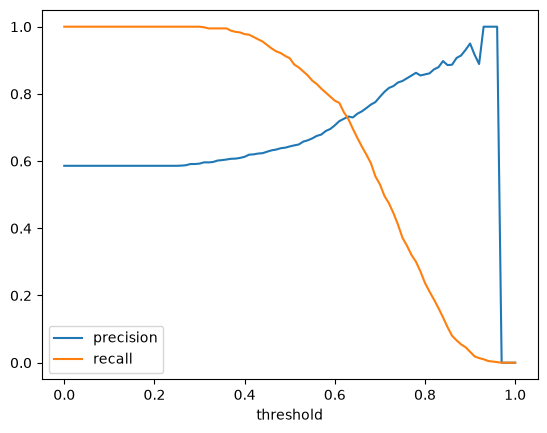

In [6]:
import matplotlib.pyplot as plt
plt.plot(s.t, s.p, label='precision'); plt.plot(s.t, s.r, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.show()